# Segmentation
Segmentation describes the process of finding cells in an image. This can be done either on the nucleus or on whole cell level. Spatialproteomics provides wrappers for `stardist` and `cellpose` (`cellpose 3` or `cellpose-SAM`).

If you want to follow along with this tutorial, you can download the data [here](https://oc.embl.de/index.php/s/XzEa9po1tjiDzzJ).

In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import spatialproteomics
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

In [3]:
# loading the input data
ds = xr.open_zarr("../../data/segmentation_example.zarr").pp[1000:1300, 1000:1300].pp.drop_layers(keep="_image")

In [4]:
# checking what the object initially looks like
ds

<xarray.Dataset> Size: 367kB
Dimensions:   (channels: 4, y: 301, x: 301)
Coordinates:
  * channels  (channels) <U11 176B 'DAPI' 'Na/K ATPase' 'CD68' 'CD11c'
  * y         (y) int64 2kB 1000 1001 1002 1003 1004 ... 1297 1298 1299 1300
  * x         (x) int64 2kB 1000 1001 1002 1003 1004 ... 1297 1298 1299 1300
Data variables:
    _image    (channels, y, x) uint8 362kB dask.array<chunksize=(4, 301, 301), meta=np.ndarray>

## Whole-Cell Segmentation with Cellpose

Cellpose can either perform segmentation on nuclei only or on whole cells, using a nuclear and a membrane marker. In this dataset, we have DAPI as a nuclear marker and Na/K ATPase as a membrane marker. In cellpose 4, the order of these does not matter. You can refer to the [cellpose documentation](https://cellpose.readthedocs.io/en/latest/settings.html) for more details to tweak the model.

In [5]:
# running the segmentation on the selected markers
ds_cellpose = ds.tl.cellpose(channel=["Na/K ATPase", "DAPI"])
ds_cellpose

Neither TORCH CUDA nor MPS version not installed/working.
>>>> using CPU
>>>> using CPU
>>>> loading model /home/meyerben/.cellpose/models/cpsam
/g/huber/users/meyerben/notebooks/codex_analysis/2024-03-18_spatialproteomics_package/spatialproteomics/.venv/lib/python3.12/site-packages/cellpose/dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:816.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


<xarray.Dataset> Size: 555kB
Dimensions:        (channels: 4, y: 301, x: 301, cells: 281, features: 2)
Coordinates:
  * channels       (channels) <U11 176B 'DAPI' 'Na/K ATPase' 'CD68' 'CD11c'
  * y              (y) int64 2kB 1000 1001 1002 1003 ... 1297 1298 1299 1300
  * x              (x) int64 2kB 1000 1001 1002 1003 ... 1297 1298 1299 1300
  * cells          (cells) int64 2kB 1 2 3 4 5 6 7 ... 276 277 278 279 280 281
  * features       (features) <U10 80B 'centroid-0' 'centroid-1'
Data variables:
    _image         (channels, y, x) uint8 362kB dask.array<chunksize=(4, 301, 301), meta=np.ndarray>
    _segmentation  (y, x) uint16 181kB 0 0 0 0 0 0 0 ... 273 273 273 273 273 0
    _obs           (cells, features) float64 4kB 1.009e+03 ... 1.004e+03

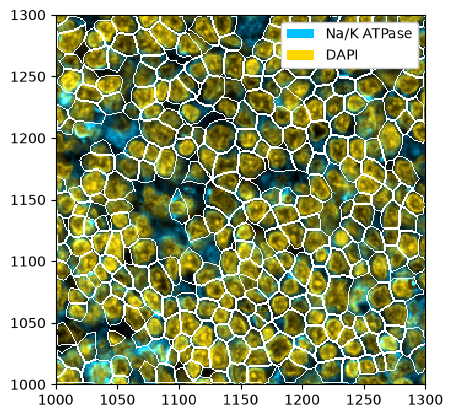

In [6]:
# for plotting, we select the two markers from before, but you could also show the other markers
_ = ds_cellpose.pp[["Na/K ATPase", "DAPI"]].pl.colorize(["deepskyblue", "gold"]).pl.show(render_segmentation=True)

## Whole-Cell Segmentation with InstanSeg
InstanSeg can use multiple fluorescent markers to segment cells. In this example, we use DAPI and a couple of membrane markers to obtain a whole-cell segmentation. You can refer to the [InstanSeg documentation](https://instanseg.github.io/instanseg/index.html) for more details to tweak the model.

In [7]:
# running the segmentation on the selected markers
ds_instanseg = ds.tl.instanseg(channel=["DAPI", "CD68", "CD11c"])
ds_instanseg

No pixel_size (in microns) was provided to InstanSeg, so the image is not rescaled to the pixel size the model was trained on. This may lead to inaccurate results.


Model fluorescence_nuclei_and_cells version 0.1.1 already downloaded in /g/huber/users/meyerben/notebooks/codex_analysis/2024-03-18_spatialproteomics_package/spatialproteomics/.venv/lib/python3.12/site-packages/instanseg/utils/../bioimageio_models/, loading
Requesting default device: cpu


/g/huber/users/meyerben/notebooks/codex_analysis/2024-03-18_spatialproteomics_package/spatialproteomics/.venv/lib/python3.12/site-packages/instanseg/inference_class.py:488: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.amp.autocast('cuda'):
/g/huber/users/meyerben/notebooks/codex_analysis/2024-03-18_spatialproteomics_package/spatialproteomics/.venv/lib/python3.12/site-packages/torch/nn/modules/module.py:1789: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:49.)
  return forward_call(*args, **kwargs)


<xarray.Dataset> Size: 1MB
Dimensions:        (channels: 4, y: 301, x: 301, cells: 349, features: 2)
Coordinates:
  * channels       (channels) <U11 176B 'DAPI' 'Na/K ATPase' 'CD68' 'CD11c'
  * y              (y) int64 2kB 1000 1001 1002 1003 ... 1297 1298 1299 1300
  * x              (x) int64 2kB 1000 1001 1002 1003 ... 1297 1298 1299 1300
  * cells          (cells) int64 3kB 1 2 3 4 5 6 7 ... 350 351 352 353 354 355
  * features       (features) <U10 80B 'centroid-0' 'centroid-1'
Data variables:
    _image         (channels, y, x) uint8 362kB dask.array<chunksize=(4, 301, 301), meta=np.ndarray>
    _segmentation  (y, x) int64 725kB 0 0 0 0 0 13 13 ... 355 355 355 355 355 0
    _obs           (cells, features) float64 6kB 1.002e+03 ... 1.288e+03

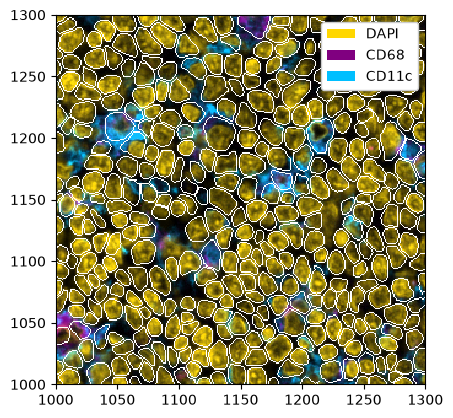

In [8]:
# for plotting, we select the three markers used in the segmentation, but you could also show other markers
_ = (
    ds_instanseg.pp[["DAPI", "CD68", "CD11c"]]
    .pl.colorize(["gold", "purple", "deepskyblue"])
    .pl.show(render_segmentation=True)
)

## Whole-Cell Segmentation with Mesmer

Segmentation with `mesmer` is deprecated, since `mesmer` only supported `python<=3.10`, which has reached its end of life in October 2026.
If you want to use it, please use `spatialproteomics<=0.8.6`.

## Nuclear Segmentation with StarDist

Sometimes, you may not have a membrane stain available. In that case, you can perform nuclear segmentation. This is possible with cellpose (simply call `tl.cellpose(channel='DAPI')`) and StarDist.
The following shows and example of how StarDist performs on such a task.

In [9]:
# running stardist
ds_stardist = ds.tl.stardist(channel="DAPI")

I0000 00:00:1793019332.312718 3615322 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793019346.496518 3615322 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793019373.309165 3615322 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793019373.373576 3615322 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will 

Found model '2D_versatile_fluo' for 'StarDist2D'.


E0000 00:00:1793019385.714826 3615322 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
I0000 00:00:1793019385.714862 3615322 cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
I0000 00:00:1793019385.714866 3615322 cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: gpu45.cluster.embl.de
I0000 00:00:1793019385.714871 3615322 cuda_diagnostics.cc:183] hostname: gpu45.cluster.embl.de
I0000 00:00:1793019385.714988 3615322 cuda_diagnostics.cc:190] libcuda reported version is: NOT_FOUND: was unable to find libcuda.so DSO loaded into this program. The library may be missing or provided via another object.
I0000 00:00:1793019385.715007 3615322 cuda_diagnostics.cc:194] kernel reported version is: 590.48.1


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.479071, nms_thresh=0.3.


100%|███████████████████████████████████████████████| 144/144 [00:21<00:00,  6.77it/s]


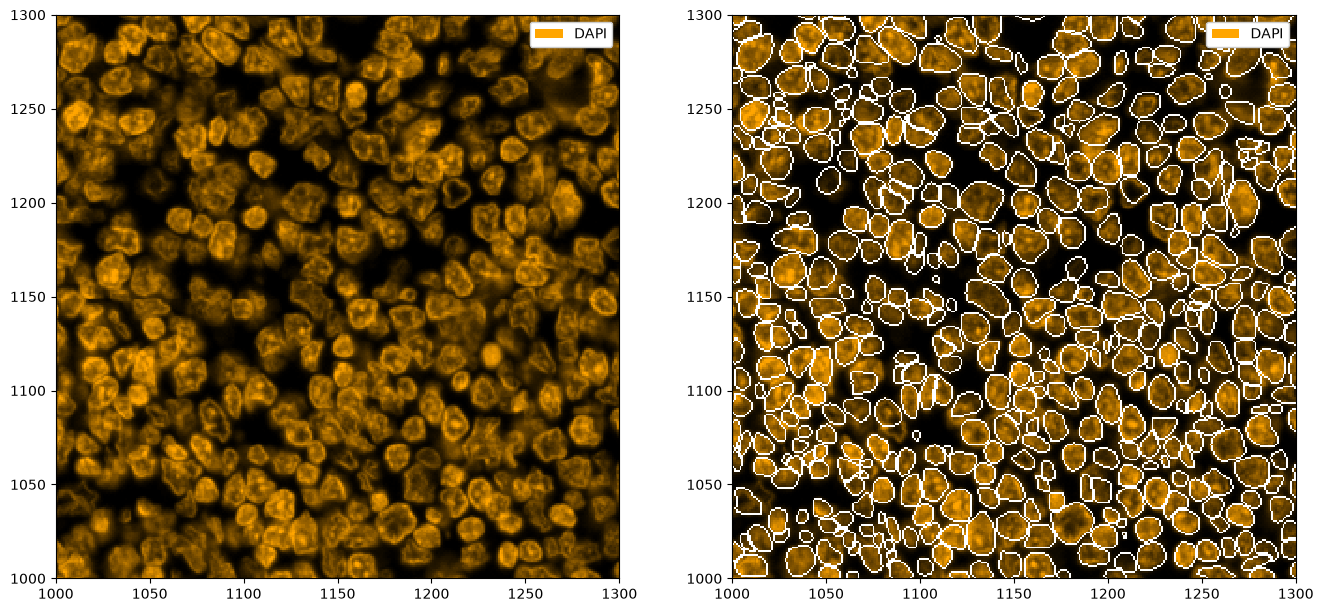

In [10]:
# plotting the segmentation
fix, ax = plt.subplots(1, 2, figsize=(16, 8))
_ = ds_stardist.pp["DAPI"].pl.colorize("orange").pl.show(ax=ax[0])
_ = ds_stardist.pp["DAPI"].pl.colorize("orange").pl.show(render_segmentation=True, ax=ax[1])

You might have noticed that StarDist tends to segment a lot of small cells. Let's look at the distribution of cell sizes, and then remove all nuclei under a certain size.

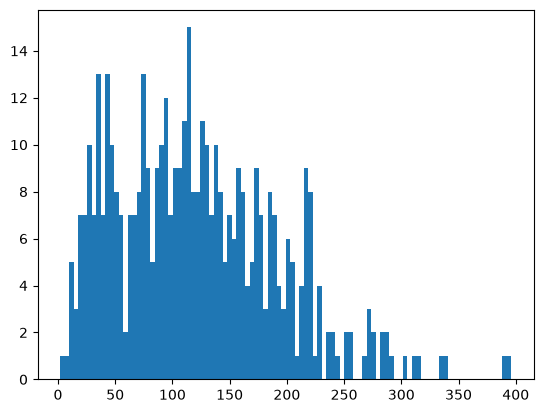

In [11]:
# getting a histogram of the areas
_ = plt.hist(ds_stardist.pp.add_observations("area").pp.get_layer_as_df()["area"], bins=100)

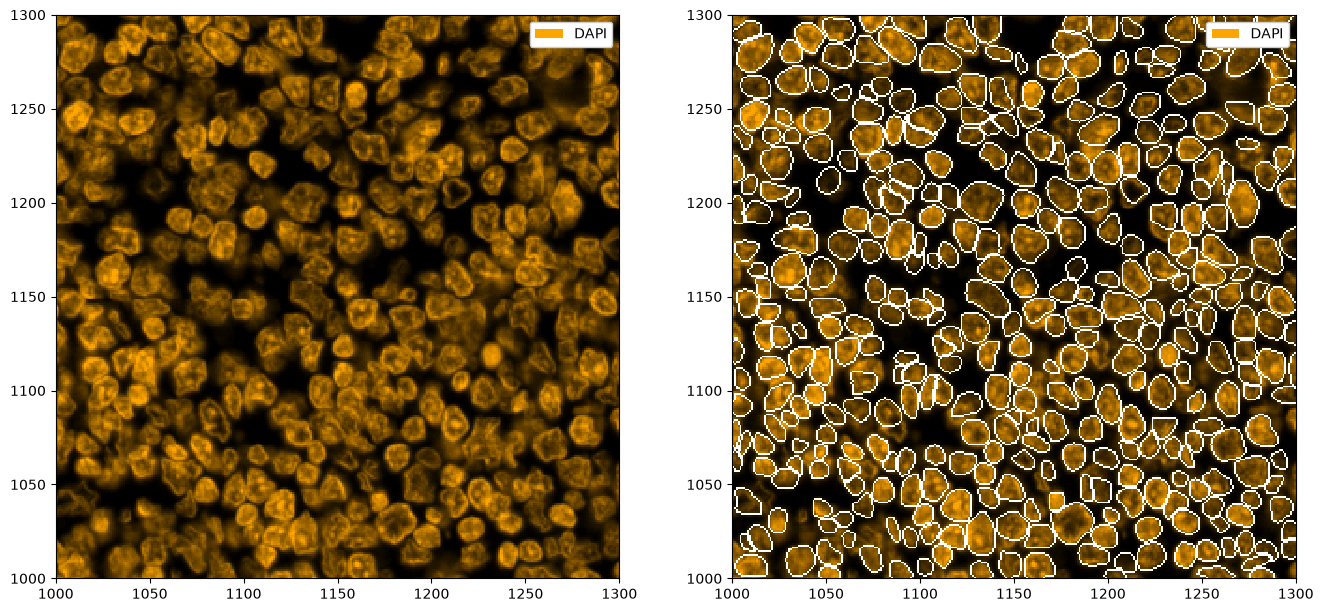

In [12]:
# removing cells which have an area below 50 pixels
ds_stardist = ds_stardist.pp.add_observations("area").pp.filter_by_obs("area", lambda x: x > 50)

# plotting the segmentation
fix, ax = plt.subplots(1, 2, figsize=(16, 8))
_ = ds_stardist.pp["DAPI"].pl.colorize("orange").pl.show(ax=ax[0])
_ = ds_stardist.pp["DAPI"].pl.colorize("orange").pl.show(render_segmentation=True, ax=ax[1])

To try to capture full cells, we can now grow the segmentation masks, e. g. by two pixels into each direction. If two masks collide, the masks will stop growing into that direction.

In [13]:
ds_stardist_grown = ds_stardist.pp.grow_cells(2)

Mask growing requires recalculation of the observations. All features other than the centroids will be removed and should be recalculated with pp.add_observations().


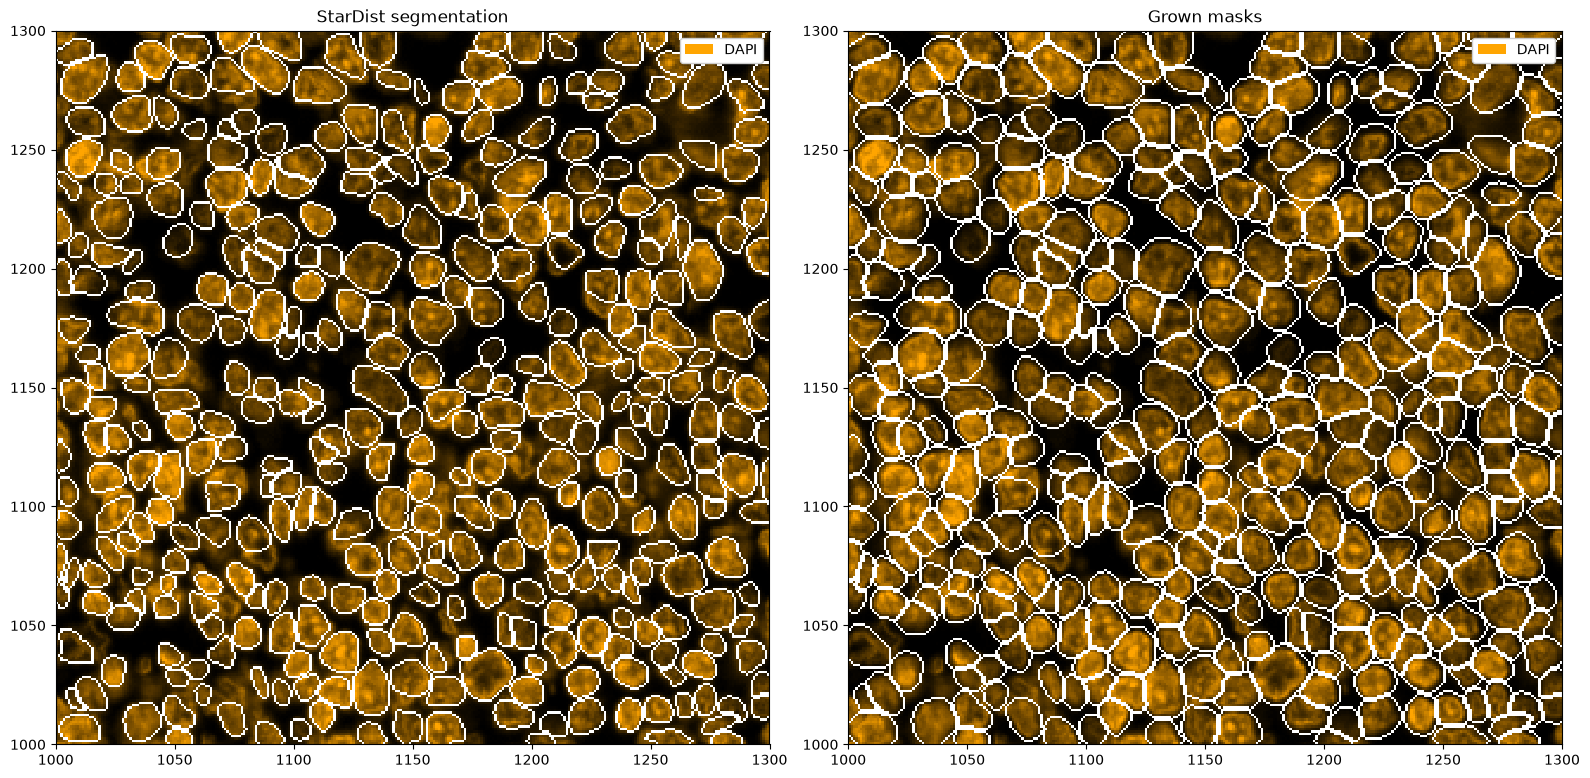

In [14]:
# plotting the segmentation
fix, ax = plt.subplots(1, 2, figsize=(16, 8))
_ = ds_stardist.pp["DAPI"].pl.colorize("orange").pl.show(render_segmentation=True, ax=ax[0])
_ = ds_stardist_grown.pp["DAPI"].pl.colorize("orange").pl.show(render_segmentation=True, ax=ax[1])
ax[0].set_title("StarDist segmentation")
ax[1].set_title("Grown masks")
plt.tight_layout()

## Segmenting Multiple Channels with Cellpose

Next to predicting nuclei or whole cells using a universal membrane marker, you can also use cellpose to try to predict other cell types. In the following, we will see how we can use cellpose to segment three different channels independently and then merge the segmentation masks into one mask. There are some hyperparameters in cellpose which can help the prediction.

In [15]:
# segmenting on DAPI, CD11c (dendritic cells) and CD68 (macrophages)
# note that when merging the masks later, the order matters (channels take precedence by position in the subsetting)
# so you should have your largest cells first, and then go down by expected size

# we use the channel_settings argument here to tell cellpose that it should perform an independent segmentation for each of our markers
# without this argument, cellpose-sam would try to segment the cells based on all three markers combined
ds_cellpose = ds.pp[["CD11c", "CD68", "DAPI"]].tl.cellpose(key_added="_cellpose_segmentation", channel_settings=[0, 0])

Neither TORCH CUDA nor MPS version not installed/working.
>>>> using CPU
>>>> using CPU
>>>> loading model /home/meyerben/.cellpose/models/cpsam
Performing independent segmentation on all markers. If you want to perform joint segmentation, please set the channel_settings argument appropriately.


In [16]:
ds_cellpose

<xarray.Dataset> Size: 820kB
Dimensions:                 (channels: 3, y: 301, x: 301)
Coordinates:
  * channels                (channels) <U11 132B 'CD11c' 'CD68' 'DAPI'
  * y                       (y) int64 2kB 1000 1001 1002 1003 ... 1298 1299 1300
  * x                       (x) int64 2kB 1000 1001 1002 1003 ... 1298 1299 1300
Data variables:
    _image                  (channels, y, x) uint8 272kB dask.array<chunksize=(3, 301, 301), meta=np.ndarray>
    _cellpose_segmentation  (channels, y, x) uint16 544kB 0 0 0 ... 311 311 311

In [17]:
# merging the segmentation masks into a single segmentation
# the threshold value tells you how much of a mask need to overlap for the less important one to be removed
# for more information on this, see next section
ds_cellpose_merged = ds_cellpose.pp.merge_segmentation(
    "_cellpose_segmentation", labels=["Dendritic Cell", "Macrophage", "Lymphocyte"]
)

In [18]:
ds_cellpose_merged

<xarray.Dataset> Size: 1MB
Dimensions:                 (channels: 3, y: 301, x: 301)
Coordinates:
  * channels                (channels) <U11 132B 'CD11c' 'CD68' 'DAPI'
  * y                       (y) int64 2kB 1000 1001 1002 1003 ... 1298 1299 1300
  * x                       (x) int64 2kB 1000 1001 1002 1003 ... 1298 1299 1300
Data variables:
    _image                  (channels, y, x) uint8 272kB dask.array<chunksize=(3, 301, 301), meta=np.ndarray>
    _cellpose_segmentation  (channels, y, x) uint16 544kB 0 0 0 ... 311 311 311
    _merged_segmentation    (y, x) uint16 181kB 0 11 11 11 ... 310 310 310 310

In [19]:
# adding the merged segmentation as the main segmentation in the object
# this is done so that we can visualize the result with pl.show(render_segmentation=True), without needing to specify which segmentation we want to show
ds_cellpose_merged = ds_cellpose_merged.pp.add_segmentation("_merged_segmentation")

In [20]:
ds_cellpose_merged

<xarray.Dataset> Size: 1MB
Dimensions:                 (labels: 3, la_props: 2, channels: 3, x: 301,
                             y: 301, cells: 315, features: 3)
Coordinates:
  * labels                  (labels) int64 24B 1 2 3
  * la_props                (la_props) <U6 48B '_color' '_name'
  * channels                (channels) <U11 132B 'CD11c' 'CD68' 'DAPI'
  * x                       (x) int64 2kB 1000 1001 1002 1003 ... 1298 1299 1300
  * y                       (y) int64 2kB 1000 1001 1002 1003 ... 1298 1299 1300
  * cells                   (cells) int64 3kB 1 2 3 4 5 ... 311 312 313 314 315
  * features                (features) <U10 120B '_labels' ... 'centroid-1'
Data variables:
    _la_properties          (labels, la_props) <U14 336B '#A079BF' ... 'Macro...
    _image                  (channels, y, x) uint8 272kB dask.array<chunksize=(3, 301, 301), meta=np.ndarray>
    _cellpose_segmentation  (channels, y, x) uint16 544kB 0 0 0 ... 311 311 311
    _merged_segmentation    (y, x) uint16 181kB 0 11 11 11 ... 310 310 310 310
    _obs                    (cells, features) float64 8kB 1.0 ... 1.004e+03
    _segmentation           (y, x) uint16 181kB 0 11 11 11 ... 310 310 310 310

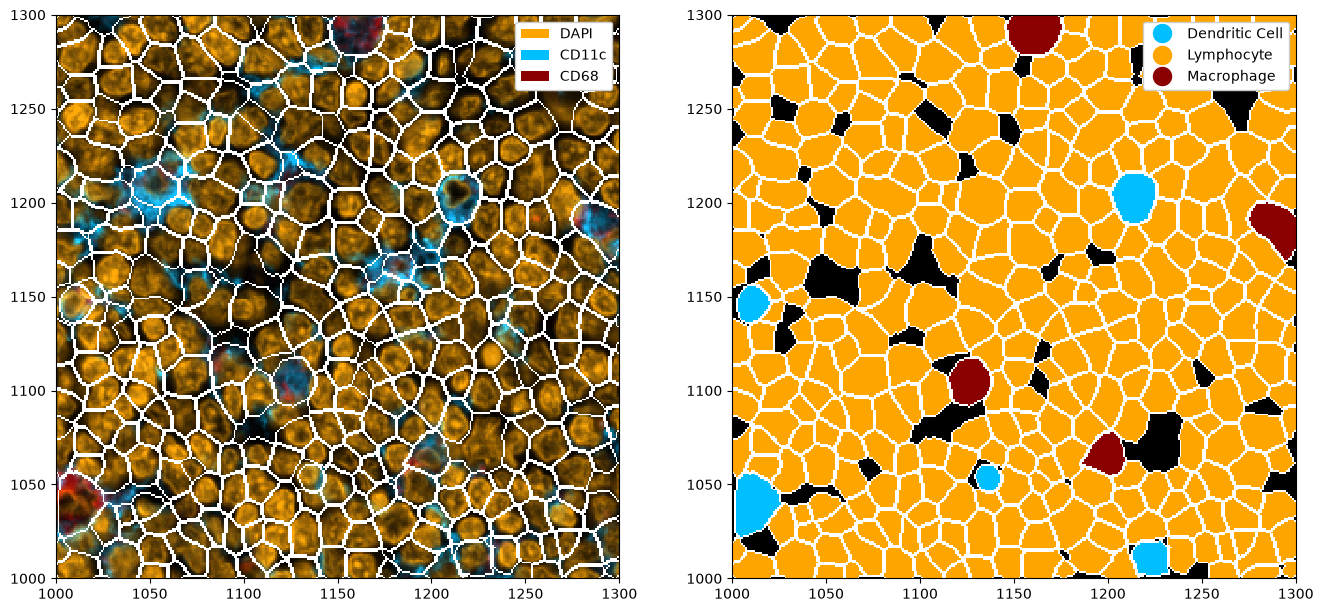

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))

# adding colors to match the channel colors
colors = ["orange", "deepskyblue", "darkred"]
ds_cellpose_merged = ds_cellpose_merged.la.set_label_colors(["Lymphocyte", "Dendritic Cell", "Macrophage"], colors)

# merged masks
_ = (
    ds_cellpose_merged.pp[["DAPI", "CD11c", "CD68"]]
    .pl.colorize(colors=colors)
    .pl.show(render_segmentation=True, ax=ax[0])
)
_ = ds_cellpose_merged.pl.show(
    render_image=False, render_segmentation=True, render_labels=True, legend_label=True, ax=ax[1]
)

## Fine-Tuning Cellpose
Cellpose often benefits from fine-tuning, which is detailed in their [documentation](https://cellpose.readthedocs.io/en/latest/gui.html#training-your-own-cellpose-model). You can load fine-tuned cellpose models into `spatialproteomics` by using `ds.tl.cellpose(channel="your_marker", pretrained_model=model_path)`.

## Merging Segmentation Masks from Different Layers

In the previous section, we looked at how to merge masks from a single layer. But what do we do if we have multiple segmentations in different layers?

Let us consider an example. We can run cellpose on our membrane stain, and then independently on the macrophages and dendritic cells. However, now our segmentation masks are stored in different layers. The good thing is, we can combine them just as easily by using `pp.merge_segmentation()`.

In [22]:
# running cellpose to obtain a bunch of different segmentation masks
# these are stored in the layers dapi_seg, macro_seg, and dendritic_seg
ds_cellpose = (
    ds.tl.cellpose(channel=["DAPI", "Na/K ATPase"], key_added="dapi_seg")
    .tl.cellpose(channel="CD68", key_added="macro_seg")
    .tl.cellpose(channel="CD11c", key_added="dendritic_seg")
)
ds_cellpose

Neither TORCH CUDA nor MPS version not installed/working.
>>>> using CPU
>>>> using CPU
>>>> loading model /home/meyerben/.cellpose/models/cpsam
Neither TORCH CUDA nor MPS version not installed/working.
>>>> using CPU
>>>> using CPU
>>>> loading model /home/meyerben/.cellpose/models/cpsam
Neither TORCH CUDA nor MPS version not installed/working.
>>>> using CPU
>>>> using CPU
>>>> loading model /home/meyerben/.cellpose/models/cpsam


<xarray.Dataset> Size: 911kB
Dimensions:        (channels: 4, y: 301, x: 301)
Coordinates:
  * channels       (channels) <U11 176B 'DAPI' 'Na/K ATPase' 'CD68' 'CD11c'
  * y              (y) int64 2kB 1000 1001 1002 1003 ... 1297 1298 1299 1300
  * x              (x) int64 2kB 1000 1001 1002 1003 ... 1297 1298 1299 1300
Data variables:
    _image         (channels, y, x) uint8 362kB dask.array<chunksize=(4, 301, 301), meta=np.ndarray>
    dapi_seg       (y, x) uint16 181kB 0 0 0 0 0 0 0 ... 281 281 281 281 281 0
    macro_seg      (y, x) uint16 181kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    dendritic_seg  (y, x) uint16 181kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0

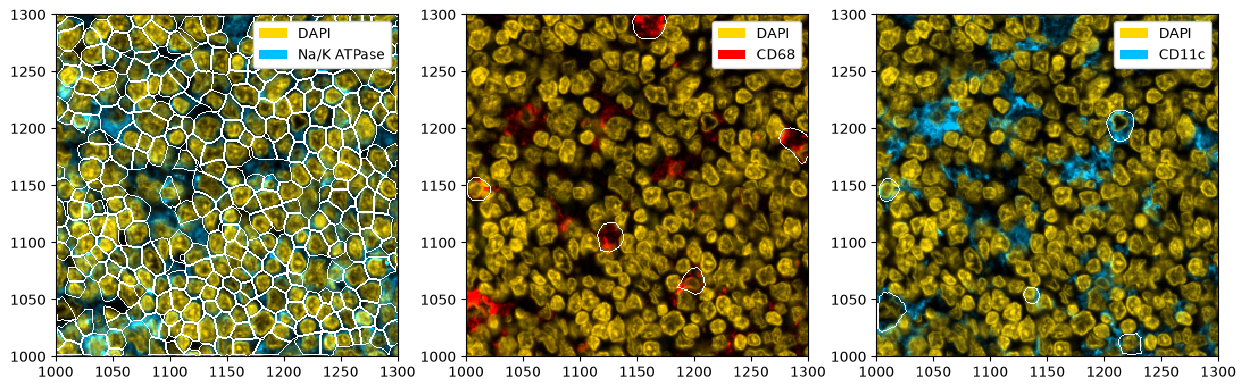

In [23]:
# plotting the individual masks
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
_ = (
    ds_cellpose.pp[["DAPI", "Na/K ATPase"]]
    .pl.colorize(["gold", "deepskyblue"])
    .pl.show(render_segmentation=True, segmentation_kwargs={"layer_key": "dapi_seg"}, ax=ax[0])
)

_ = (
    ds_cellpose.pp[["DAPI", "CD68"]]
    .pl.colorize(["gold", "red"])
    .pl.show(render_segmentation=True, segmentation_kwargs={"layer_key": "macro_seg"}, ax=ax[1])
)

_ = (
    ds_cellpose.pp[["DAPI", "CD11c"]]
    .pl.colorize(["gold", "deepskyblue"])
    .pl.show(render_segmentation=True, segmentation_kwargs={"layer_key": "dendritic_seg"}, ax=ax[2])
)

In brief, `pp.merge_segmentation()` works like this:

1. Assume two segmentation masks, $S_1$ (higher priority, e.g., macrophages) and $S_2$ (lower priority, e.g., lymphocytes)
2. We start by copying the segmentation regions from $S_2$ into $S_1$, but only for pixels where $S_1$ has background
3. Some $S_2$ cells may now be partially overwritten by $S_1$ cells — we drop any $S_2$ cell where less than `threshold1` fraction of its original area survived (e.g. with `threshold1=0.9`, an $S_2$ cell that lost more than 10% of its area to $S_1$ is discarded)
4. Of the remaining $S_2$ cells, we additionally drop any that overlap with `threshold2` or more of any single $S_1$ cell's area — this prevents $S_2$ cells from being retained when they largely encapsulate an $S_1$ cell (e.g. with `threshold2=0.9`, an $S_2$ cell is discarded if it covers more than 90% of any $S_1$ cell)
5. The surviving $S_1$ and $S_2$ regions are combined into a final mask with sequential labels

If you have more than two segmentation mask, this process is run iteratively until all segmentations have been merged into one.

Depending on what segmentation masks you have available, you might want to tweak `threshold1` and `threshold2` to be suitable to your data.

In [24]:
# merging the segmentation masks and making the merged segmentation the default one
ds_cellpose = ds_cellpose.pp.merge_segmentation(
    layer_key=["dendritic_seg", "macro_seg", "dapi_seg"],
    labels=["Dendritic Cell", "Macrophage", "Lymphocyte"],
    threshold1=0.6,
    threshold2=0.9,
).pp.add_segmentation("_merged_segmentation")

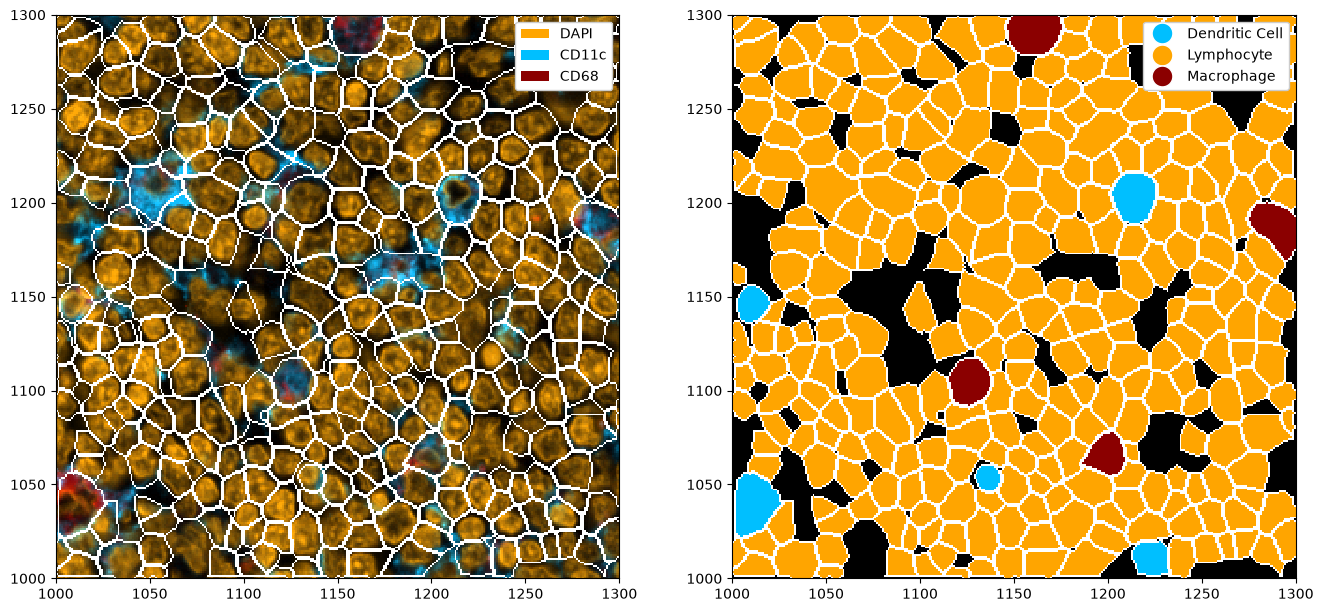

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))

# adding colors to match the channel colors
colors = ["orange", "deepskyblue", "darkred"]
ds_cellpose = ds_cellpose.la.set_label_colors(["Lymphocyte", "Dendritic Cell", "Macrophage"], colors)

# merged masks
_ = ds_cellpose.pp[["DAPI", "CD11c", "CD68"]].pl.colorize(colors=colors).pl.show(render_segmentation=True, ax=ax[0])
_ = ds_cellpose.pl.show(render_image=False, render_segmentation=True, render_labels=True, legend_label=True, ax=ax[1])